**RMSprop (Root Mean Square Propagation)** is an adaptive learning rate optimization algorithm designed to solve a major flaw in earlier optimizers by dynamically scaling the step size for every individual parameter.

---

### Definition

**RMSprop** is an optimization method that maintains a moving (exponentially decaying) average of squared gradients for each weight. It divides the learning rate by the square root of this average, allowing the model to take large steps on gentle slopes and small steps on steep, oscillating slopes.

---

### The Problem RMSprop Solved (Before AdaGrad)

To understand RMSprop, you have to understand what came right before it: **AdaGrad** (Adaptive Gradient Algorithm).

* AdaGrad was revolutionary because it gave every parameter its own learning rate based on historical gradients.
* **The Flaw:** AdaGrad accumulated *every past squared gradient* from the very first epoch to the current one. Because squares are always positive, this running sum grew larger and larger indefinitely. As a result, the effective learning rate shrank closer and closer to zero, causing training to grind to a complete halt prematurely.

**RMSprop was invented by Geoffrey Hinton** specifically to fix this flaw by replacing the cumulative sum with an **exponentially decaying moving average**, giving more weight to *recent* gradients and forgetting ancient history.

---

### How RMSprop Works (The Mechanism)

At every training step $t$, RMSprop performs three key calculations:

1. **Compute the Gradient ($g_t$):** Calculate the gradient of the loss function for the current mini-batch.
2. **Update the Moving Average of Squared Gradients ($v_t$):**

$$v_t = \beta v_{t-1} + (1 - \beta) g_t^2$$


* Where $\beta$ is the decay/forgetting factor (typically set to $0.9$). This ensures that old gradients fade away, preventing the denominator from growing infinitely.


3. **Update the Weights ($w_t$):**

$$w_{t+1} = w_t - \frac{\eta}{\sqrt{v_t} + \epsilon} \odot g_t$$


* Where $\eta$ is the base learning rate, $\epsilon$ (epsilon) is a tiny number (e.g., $10^{-8}$) to prevent division by zero, and $\odot$ denotes element-wise multiplication.



#### Why This Works Brilliantly:

* If a parameter experiences **consistently large, erratic gradients** (steep walls), $v_t$ becomes large. Dividing by a large number ($\sqrt{v_t}$) shrinks the effective learning rate, calming down the oscillations.
* If a parameter experiences **small, consistent gradients** (gentle slopes), $v_t$ stays small. Dividing by a small number boosts the effective learning rate, accelerating progress across plateaus.

---

### Where Is RMSprop Used Today?

* **Recurrent Neural Networks (RNNs & LSTMs):** Historically, RMSprop was the go-to optimizer for sequence models because it handles non-stationary gradients in recurrent connections exceptionally well.
* **Reinforcement Learning (RL):** It remains a favorite optimizer for deep reinforcement learning algorithms (like DQN and PPO) because reward landscapes in RL change dynamically as the agent learns.
* **The Ancestor of Adam:** RMSprop is fundamentally important because **Adam is essentially RMSprop combined with Momentum**. Adam took RMSprop's second moment (variance tracking) and paired it with SGD's first moment (momentum tracking).

---

### PyTorch Implementation

Here is how you initialize and use RMSprop in PyTorch:

In [1]:
# Import necessary libraries
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)
print("Libraries imported successfully!")

Libraries imported successfully!


### Step 1: Library Setup and Reproducibility

In this initial cell, we set up the environment required for our PyTorch machine learning pipeline:

* **PyTorch Core (`torch`, `nn`, `optim`)**: PyTorch is our deep learning framework. `nn` contains neural network layers (like Linear and ReLU), while `optim` provides optimization algorithms (including RMSprop).
* **Scikit-Learn (`make_classification`, `train_test_split`, `StandardScaler`)**: We leverage classical machine learning utilities to generate mock classification data, split it into validation sets, and scale our features.
* **Reproducibility**: Deep learning training runs can be stochastic due to random initialization of weights. By setting `torch.manual_seed(42)` and `np.random.seed(42)`, we guarantee that every run produces identical results, ensuring reliability when debugging or comparing optimizers.

In [2]:
# Generate synthetic vehicle telemetry dataset (4 features, 3 classes)
X_raw, y_raw = make_classification(
    n_samples=2000,
    n_features=4,
    n_informative=4,
    n_redundant=0,
    n_classes=3,
    random_state=42
)

# Split into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (1600, 4)
Testing set shape: (400, 4)


### Step 2: Synthetic Dataset Generation

To demonstrate the optimizer's power, we create a synthetic dataset mimicking **vehicle telemetry data**:

* **Features ($N=4$):** Four continuous numeric inputs (e.g., engine RPM, oil pressure, gear ratio, and vibration metrics).
* **Targets ($C=3$):** A multi-class categorization task where the model must assign each vehicle instance to one of three possible statuses (e.g., `0: Normal Operation`, `1: Maintenance Required`, `2: Critical Failure`).
* **Splitting:** We partition the 2,000 generated samples into an **80/20 train-test split**. The training set is used to optimize the weights, while the independent test set evaluates how well the model generalizes to unseen scenarios.

In [3]:
# Standardize features (crucial for adaptive optimizers like RMSprop)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert numpy arrays to PyTorch Tensors
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.long)

print("Data scaled and converted to PyTorch Tensors.")

Data scaled and converted to PyTorch Tensors.


### Step 3: Feature Scaling & PyTorch Tensor Conversion

#### Why Scaling is Mandatory for Adaptive Optimizers (like RMSprop)

Optimizers that compute moving averages of squared gradients are highly sensitive to the scale of input features.
* If Feature $A$ ranges from $[0, 1]$ and Feature $B$ ranges from $[0, 1000]$, the gradients with respect to weights associated with Feature $B$ will be vastly larger.
* This leads to highly asymmetric loss landscapes (elongated ravines), forcing the optimizer to use extremely small learning rates to prevent exploding gradients.

$$\text{Standardization: } X_{\text{scaled}} = \frac{X - \mu}{\sigma}$$

By ensuring every input feature has a **mean of 0** and a **variance of 1**, we create a balanced loss landscape that lets RMSprop adjust step sizes smoothly across all parameter dimensions.

Finally, the NumPy arrays are wrapped in `torch.tensor` format to support GPU acceleration and automatic differentiation via PyTorch's autograd engine.

In [4]:
class VehicleMLP(nn.Module):
    def __init__(self):
        super(VehicleMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(4, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 3) # Outputs raw logits for 3 classes
        )

    def forward(self, x):
        return self.network(x)

model = VehicleMLP()
print(model)

VehicleMLP(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Linear(in_features=16, out_features=3, bias=True)
  )
)


### Step 4: Model Architecture Design

We construct a classic Feedforward Neural Network, specifically a **Multi-Layer Perceptron (MLP)**, for our 3-class classification problem. Here is a visual logical flow of the network layers:

```
[Input: 4 Features]
       │
       ▼
[Linear Layer: 4 ──> 32 Neurons]
       │
       ▼
[Activation: ReLU (Rectified Linear Unit)]
       │
       ▼
[Regularization: Dropout (20% rate)] ──> Prevents overfitting by randomly silencing nodes
       │
       ▼
[Linear Layer: 32 ──> 16 Neurons]
       │
       ▼
[Activation: ReLU]
       │
       ▼
[Output Layer: 16 ──> 3 Raw Logits]
```

* **Dropout:** During training, 20% of the active neurons in the hidden layer are randomly set to zero. This prevents the network from relying too heavily on any single feature combination, promoting robust generalization.
* **Output:** Notice that the final linear layer has **3 outputs** (matching our classes) and does *not* apply a Softmax activation. In PyTorch, the standard classification loss function is designed to ingest raw outputs (logits) directly.

In [5]:
# Loss function
criterion = nn.CrossEntropyLoss()

# RMSprop Optimizer (adaptive learning rate with moving average of squared gradients)
optimizer = optim.RMSprop(
    model.parameters(),
    lr=0.001,          # Base learning rate (typically smaller for RMSprop than SGD)
    alpha=0.9,         # Smoothing constant (decay rate for moving average)
    weight_decay=1e-4  # L2 regularization
)

# Exponential Learning Rate Scheduler (decays LR slightly every epoch)
scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.98)

print("Optimizer and Scheduler initialized.")

Optimizer and Scheduler initialized.


### Step 5: Optimization & Scheduling Strategy

#### Loss Function
* **Cross-Entropy Loss (`nn.CrossEntropyLoss`)**: Combines a Log-Softmax function and negative log-likelihood loss under the hood. It measures the divergence between the model's predicted class probability distribution and the actual true labels.

#### RMSprop Configuration
We initialize `optim.RMSprop` with specific hyperparameter choices:
* `lr=0.001`: The base step size $\eta$. Adaptive optimizers generally need a lower base rate than standard SGD.
* `alpha=0.9`: Represents the decay constant $\beta$. It dictates how heavily historical gradients influence current step scaling:
  $$v_t = 0.9 v_{t-1} + 0.1 g_t^2$$
  A value of `0.9` means the running average focuses heavily on the most recent ~10 gradient steps.
* `weight_decay=1e-4`: Adds an $L2$ penalty on the model weights to suppress weight explosion and combat overfitting.

#### Learning Rate Scheduler
* **ExponentialLR**: Decays the base learning rate exponentially by multiplying it by $\gamma$ (gamma) at the end of every epoch:
  $$\text{LR}_{\text{new}} = \text{LR}_{\text{old}} \times 0.98$$
  This helps the optimizer aggressively find promising directions early in training with larger steps, then gradually "cools down" to micro-step closer to the global minimum as training concludes.

In [6]:
epochs = 100
loss_history = []
lr_history = []

print("--- Starting Training with RMSprop ---")
for epoch in range(epochs):
    model.train()

    # Forward pass
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)

    # Backward pass & optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Track metrics
    current_lr = scheduler.get_last_lr()[0]
    lr_history.append(current_lr)
    loss_history.append(loss.item())

    # Step the scheduler
    scheduler.step()

    if (epoch + 1) % 20 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | Loss: {loss.item():.4f} | LR: {current_lr:.5f}")

print("Training complete!")

--- Starting Training with RMSprop ---
Epoch [20/100] | Loss: 1.0486 | LR: 0.00068
Epoch [40/100] | Loss: 0.9993 | LR: 0.00045
Epoch [60/100] | Loss: 0.9669 | LR: 0.00030
Epoch [80/100] | Loss: 0.9443 | LR: 0.00020
Epoch [100/100] | Loss: 0.9332 | LR: 0.00014
Training complete!


### Step 6: The PyTorch Training Loop

This cell executes the core iterative training process over 100 full passes (epochs) through the dataset:

1. **Set training mode (`model.train()`)**: Activates layers that behave differently during training vs inference, such as enabling our **Dropout** layer.
2. **Zero Gradients (`optimizer.zero_grad()`)**: PyTorch accumulates gradients by default on backward passes. We must clear old gradients before computing new ones.
3. **Forward Pass (`model(X_train_t)`)**: Feeds the input tensors forward through the MLP layers to predict target classes.
4. **Calculate Loss**: Evaluates the output logits against the ground truth labels.
5. **Backward Pass (`loss.backward()`)**: Computes the derivative of the loss with respect to all model weights via backpropagation.
6. **Optimizer Step (`optimizer.step()`)**: Updates the weights using the RMSprop formula, adjusting step sizes independently for each parameter based on their running gradient variance.
7. **Scheduler Step (`scheduler.step()`)**: Updates the learning rate according to our exponential decay curve ($
	ext{LR} \leftarrow \text{LR} \times 0.98$).

In [7]:
model.eval()
with torch.no_grad():
    test_outputs = model(X_test_t)
    _, predicted = torch.max(test_outputs, 1)
    accuracy = (predicted == y_test_t).sum().item() / y_test_t.size(0)
    print(f"\nFinal Test Accuracy: {accuracy * 100:.2f}%")


Final Test Accuracy: 68.00%


### Step 7: Model Inference & Test Accuracy

To assess the model's final predictive performance, we evaluate it on the testing set:

* **`model.eval()`**: Deactivates training-specific behaviors like **Dropout**, forcing the model to act deterministically.
* **`torch.no_grad()`**: Disables PyTorch's automatic differentiation graph tracking engine. Since we are only predicting classes and not optimizing weights, skipping gradient computation drastically reduces memory overhead and accelerates computation.
* **Accuracy:** We find the maximum predicted logit score for each sample, compare it to the true label, and calculate the overall percentage of correct predictions.

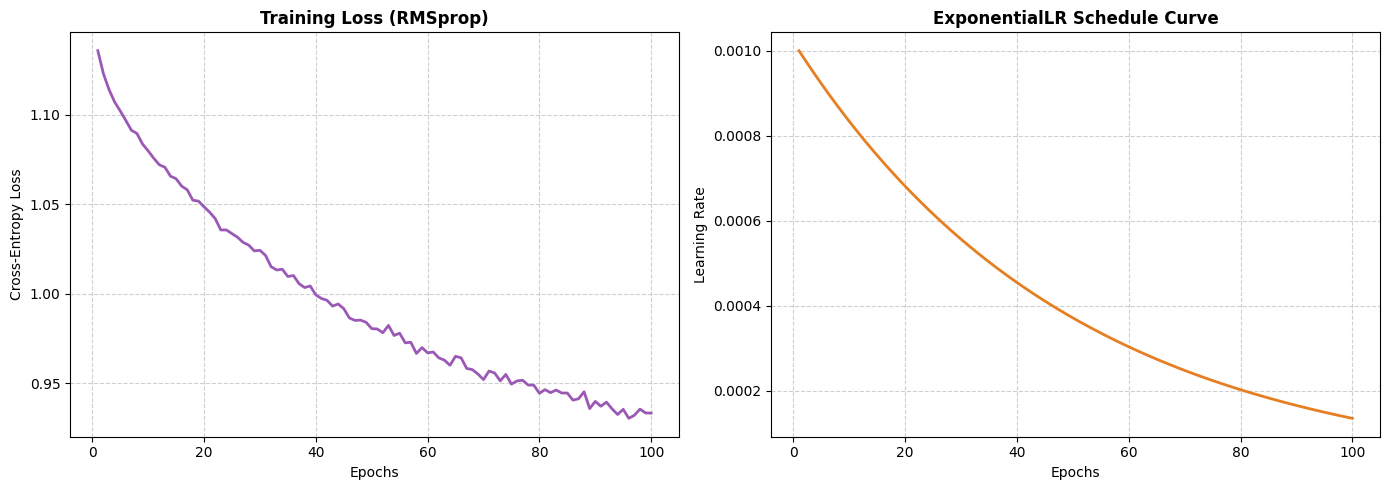

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Training Loss
axes[0].plot(range(1, epochs + 1), loss_history, color='#9b59b6', linewidth=2)
axes[0].set_title('Training Loss (RMSprop)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epochs', fontsize=10)
axes[0].set_ylabel('Cross-Entropy Loss', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot Learning Rate Schedule (Exponential decay curve)
axes[1].plot(range(1, epochs + 1), lr_history, color='#e67e22', linewidth=2)
axes[1].set_title('ExponentialLR Schedule Curve', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epochs', fontsize=10)
axes[1].set_ylabel('Learning Rate', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Step 8: Visualizing Optimization Dynamics

The dual plotting layout gives us a visual window into our optimization strategy:

* **Left Graph (Training Loss Curve)**: Displays the training loss across 100 epochs. The steep downward trajectory demonstrates how quickly RMSprop scales updates in flat regions to find steep descent paths. Notice how the curve stabilizes and flattens out towards the end, showing convergence.
* **Right Graph (Exponential Decay Schedule)**: Illustrates the decay curve controlled by our learning rate scheduler. Starting at $0.001$, the learning rate decreases steadily to approximately $0.00013$ by epoch 100. This gradual descent helps the model stabilize within its optimal local minimum without overshooting the valley.